In [1]:
import matplotlib.pyplot as plt
import numpy as np

from functions import *

# Consideration
To model the effect of temporally uncorrelated noise in the system (photons that arrive at random times) we consider they offer a similar effect to the temporally correlated noise. We explain this for the individual methods :

### Area
We believe this is true in the case of area, since to some approximation the area assigns the total number of photons that hit the detector in the time interval of the full trace. Therefore, is the randomly occurring photons follow Poisson statistics that final generated distribution consider an additional Poisson contribution that is equivalent to the typical temporally correlated noise.

### PCA
It is still true for PCA since the method acts similarly to the area with the slight difference that the considered time window is smaller and weights the traces following the first principal component. It becomes a bit hard to say if this is a good approximation to consider the photon number misalignments using the typical noise model, but PCA should filter a significant portion of the noise and exist somewhere between UMAP and the area.

### UMAP
In principle the temporally uncorrelated noise photons should almost be perfectly removed.

# Experimental Reference

We define the experimental joint probability distribution in the case of a noisy source that is analyzed using UMAP.

In [2]:
# Experimental reference using UMAP for low noise
H_ref = np.array([[4.07592e-01, 1.29801e-01, 2.83160e-02, 5.46800e-03, 1.07500e-03,
        2.09000e-04, 4.40000e-05],
       [1.51658e-01, 9.00330e-02, 3.12050e-02, 8.62800e-03, 2.16100e-03,
        5.55000e-04, 1.40000e-04],
       [3.47570e-02, 3.44940e-02, 1.78150e-02, 6.77500e-03, 2.22400e-03,
        6.96000e-04, 2.31000e-04],
       [7.53800e-03, 1.03390e-02, 7.54200e-03, 3.84000e-03, 1.60700e-03,
        6.21000e-04, 2.57000e-04],
       [1.47400e-03, 2.59900e-03, 2.57000e-03, 1.59600e-03, 8.57000e-04,
        3.89000e-04, 2.06000e-04],
       [3.06000e-04, 7.02000e-04, 7.61000e-04, 6.88000e-04, 4.11000e-04,
        2.24000e-04, 1.30000e-04],
       [6.90000e-05, 2.06000e-04, 3.19000e-04, 2.91000e-04, 2.43000e-04,
        1.72000e-04, 1.66000e-04]])

# Approximation for the squeezing params

We first fit the function to get an approximation for the squeezing paarameters.

In [3]:
N = 15
guess = {
    "eta_s": 0.7,
    "eta_i": 0.7,   
    "sq_0": 0.3,
    "sq_1": 0.2,
    "noise_s": 0.1,
    "noise_i": 0.1,
    "n_modes": 1,
}
params = fit_2d(
    H_ref[:N, :N] / H_ref[:N, :N].sum(),
    guess,
    do_not_vary=None,#['eta_s', 'eta_i'],
    method="leastsq",
    threshold=False,
    cutoff=N,
    sq_label="sq_",
    noise_label="noise"
)
params

## Visual Validation

We validate visually that the joint distributions are similar.

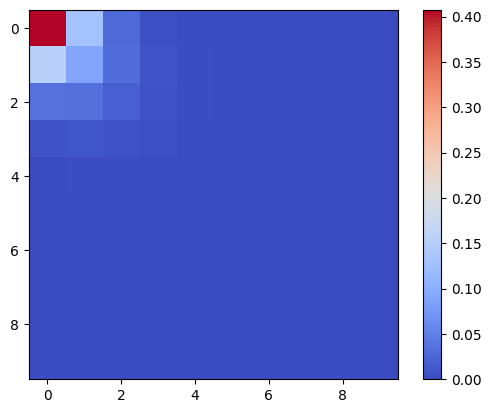

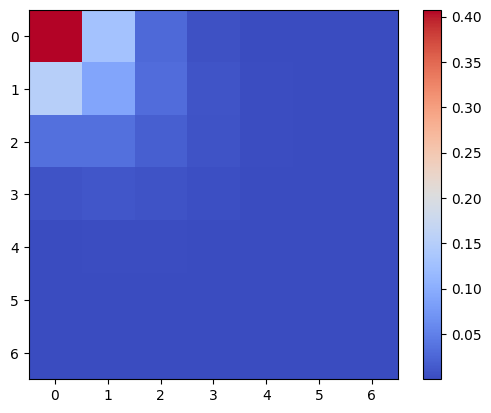

In [4]:
params_ = params.params
pmf = twinbeam_pmf(params_, cutoff=10)

plt.imshow(pmf, cmap='coolwarm', interpolation='nearest')
plt.colorbar()
plt.show()

plt.imshow(H_ref, cmap='coolwarm', interpolation='nearest')
plt.colorbar()
plt.show()

## Numerical Validation
We look at the similarity between the $g^{(2)}(0)$ computed on the fitted and experimental distributions. 
We can observe a slight difference that will be addressed by the next step.

In [5]:
print(f'Fit NRF:{compute_nrf(pmf)}, g2:{compute_g2(np.sum(pmf, axis=1))}')
print(f'Experiment NRF:{compute_nrf(H_ref)}, g2:{compute_g2(np.sum(H_ref, axis=1))}')

Fit NRF:0.8079762014184025, g2:1.3875416421169295
Experiment NRF:0.8117820840449324, g2:1.4999952053784489


# Effect of Noise and Loss
To look at the scaling of loss and noise in the system, we use the squeezing parameters and from this point plot the effect of loss and noise on the $g^{(2)}(0)$ and NRF. 

We use the $g^{(2)}(0)$ and NRF as a reference to find a secnario that approximatly describes our experiment by computing 
$$
\text{argmin}(|g^{(2)}_{\text{channel 1}} - 1.699)| + |g^{(2)}_{\text{channel 2}} - 1.699| + |NRF - 0.811|),
$$
where the numerical values are the experimental results using UMAP. We select the loss value that is most likely to be associated with our experiement and use this line to visualize the scaling of the $g^{(2)}(0)$ and NRF.

In [6]:
noise = np.linspace(0., 2, 100)
loss = np.linspace(0., 1, 100)

nrf_values = np.zeros((len(noise), len(loss)))
g2_values1 = np.zeros((len(noise), len(loss)))
g2_values2 = np.zeros((len(noise), len(loss)))
for i, n in enumerate(noise):
    for j, l in enumerate(loss):
        params_ = params.params.copy()
        params_["eta_s"].value = 1 - l
        params_["eta_i"].value = 1 - l
        params_["noise_s"].value = n
        params_["noise_i"].value = n
        pmf = twinbeam_pmf(params_, cutoff=N)
        g2_values1[i, j] = compute_g2(pmf.sum(axis=1))
        g2_values2[i, j] = compute_g2(pmf.sum(axis=0))
        nrf_values[i, j] = compute_nrf(pmf)

eta_s_val = params.params["eta_s"].value
noise_s_val = params.params["noise_s"].value

Loss: 0.7777777777777778
Noise: 0.06060606060606061
Index of closest loss to 1 - eta_s: (3, 77)


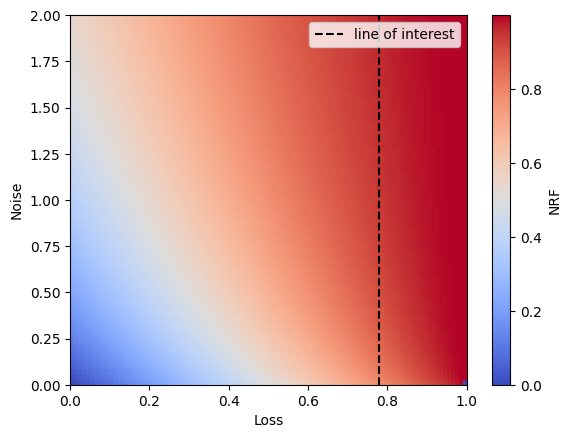

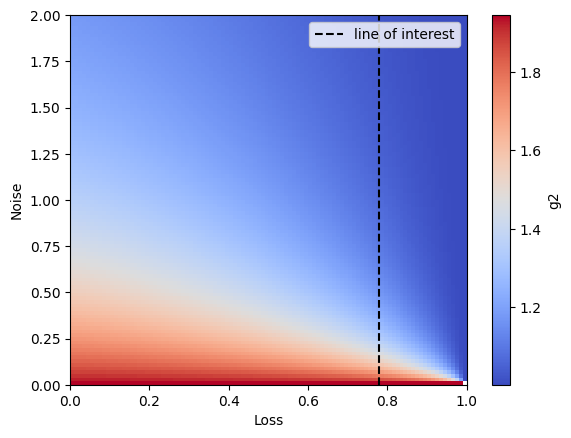

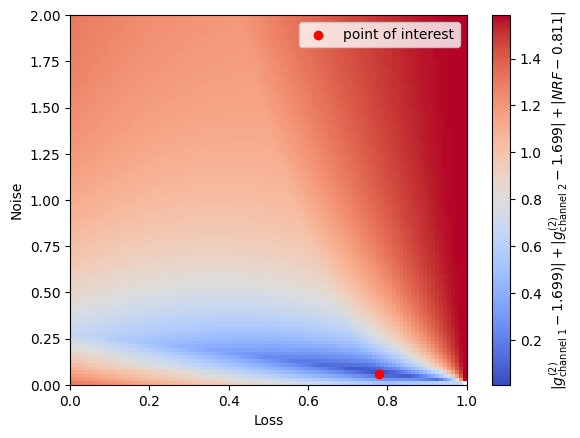

In [7]:
opt = np.abs(g2_values1 - 1.699) + np.abs(g2_values2 - 1.699) + np.abs(nrf_values - 0.811)
idx = np.unravel_index(np.nanargmin(opt), opt.shape)
idx_loss = idx[1]

print("Loss:", loss[idx_loss])
print("Noise:", noise[idx[0]])
print("Index of closest loss to 1 - eta_s:", idx)

plt.imshow(nrf_values, extent=(0, loss.max(), 0, noise.max()), origin='lower', aspect='auto', cmap='coolwarm')
plt.vlines(loss[idx_loss], 0, noise.max(), color='black', linestyle='--', label='line of interest')
plt.colorbar(label='NRF')
plt.xlabel('Loss')
plt.ylabel('Noise')
plt.legend()
plt.show()

plt.imshow(g2_values1, extent=(0, loss.max(), 0, noise.max()), origin='lower', aspect='auto', cmap='coolwarm')
plt.vlines(loss[idx_loss], 0, noise.max(), color='black', linestyle='--', label='line of interest')
plt.colorbar(label='g2')
plt.xlabel('Loss')
plt.ylabel('Noise')
plt.legend()
plt.show()

plt.imshow(opt, extent=(0, loss.max(), 0, noise.max()), origin='lower', aspect='auto', cmap='coolwarm')
plt.colorbar(label=r'|$g^{(2)}_{\text{channel 1}} - 1.699)| + |g^{(2)}_{\text{channel 2}} - 1.699| + |NRF - 0.811|$')
plt.scatter(loss[idx_loss], noise[idx[0]], color='red', label='point of interest')
plt.xlabel('Loss')
plt.ylabel('Noise')
plt.legend()
plt.show()

# Scaling
For our loss scenario we can plot the effect of noise of our parameters of interest and observe that the NRF is not as sensitive to noise compared with the $g^{(2)}(0)$. By following where the different techniques fall on this function by finding there position based on the $g^{(2)}(0)$, we find that the NRF is not far from the values we computed experimentally but most importantly that the NRF is less sensitive to noise compared with the $g^{(2)}(0)$.

noNoise g2: 1.8524449848152205, noNoise nrf: 0.789062345757523
Noise umap g2: 1.7026833487338726, Noise umap nrf: 0.8085102722544018
Noise pca g2: 1.5892214027469826, Noise pca nrf: 0.8246748174885438
Noise area g2: 1.4644337942622132, Noise area nrf: 0.8443797669900044


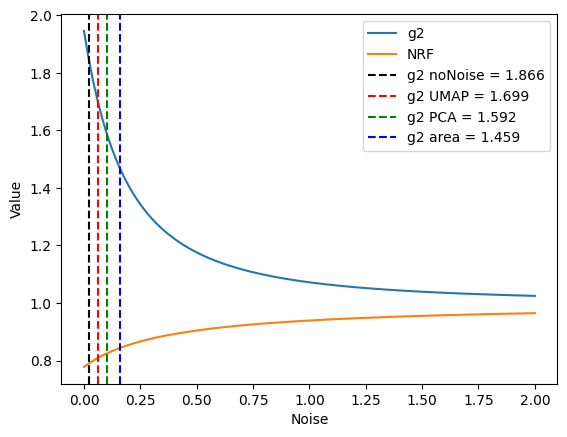

In [8]:
idx_noNoise = np.argmin(np.abs(g2_values1[:, idx_loss] - 1.866))
idx_Noise_umap = np.argmin(np.abs(g2_values1[:, idx_loss] - 1.699))
idx_Noise_pca = np.argmin(np.abs(g2_values1[:, idx_loss] - 1.592))
idx_Noise_area = np.argmin(np.abs(g2_values1[:, idx_loss] - 1.459))

print(f"noNoise g2: {g2_values1[idx_noNoise, idx_loss]}, noNoise nrf: {nrf_values[idx_noNoise, idx_loss]}")
print(f"Noise umap g2: {g2_values1[idx_Noise_umap, idx_loss]}, Noise umap nrf: {nrf_values[idx_Noise_umap, idx_loss]}")
print(f"Noise pca g2: {g2_values1[idx_Noise_pca, idx_loss]}, Noise pca nrf: {nrf_values[idx_Noise_pca, idx_loss]}")
print(f"Noise area g2: {g2_values1[idx_Noise_area, idx_loss]}, Noise area nrf: {nrf_values[idx_Noise_area, idx_loss]}")

plt.plot(noise, g2_values1[:, idx_loss], label='g2')
plt.plot(noise, nrf_values[:, idx_loss], label='NRF')
plt.axvline(noise[idx_noNoise], color='black', linestyle='--', label='g2 noNoise = 1.866')
plt.axvline(noise[idx_Noise_umap], color='red', linestyle='--', label='g2 UMAP = 1.699')
plt.axvline(noise[idx_Noise_pca], color='green', linestyle='--', label='g2 PCA = 1.592')
plt.axvline(noise[idx_Noise_area], color='blue', linestyle='--', label='g2 area = 1.459')
plt.xlabel('Noise')
plt.ylabel('Value')
plt.legend()
plt.show()

# Distribution Differences
We look at the differences between the different combinations of joint distributions and see an asymmetry in the experimental reference due to a channel being more lossy.

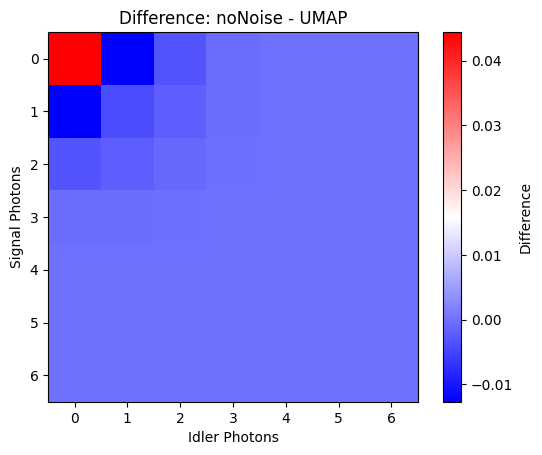

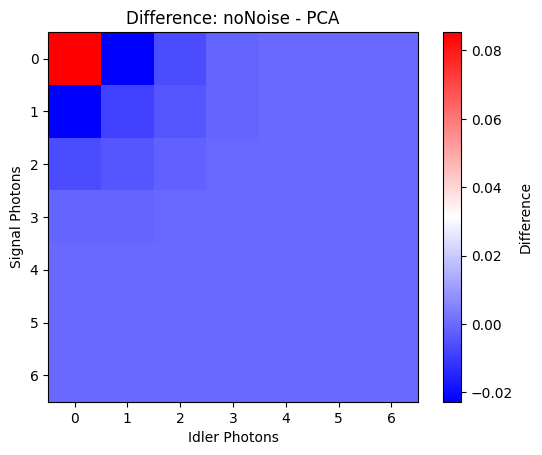

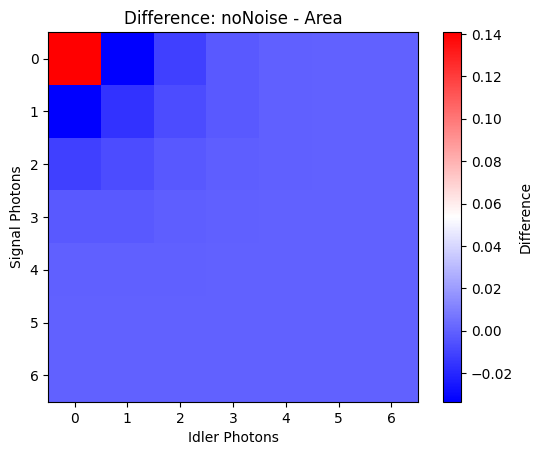

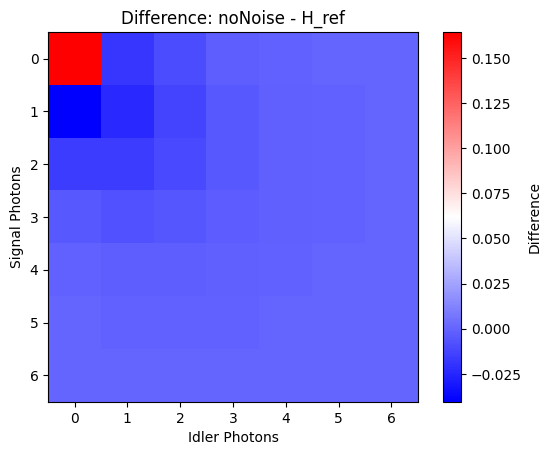

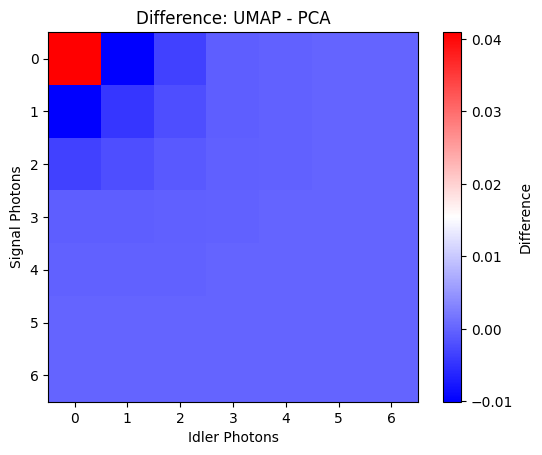

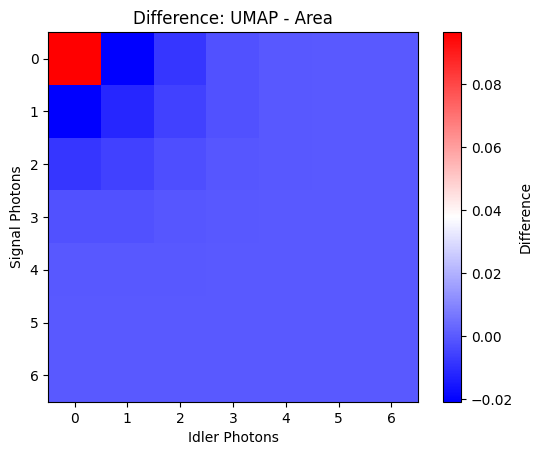

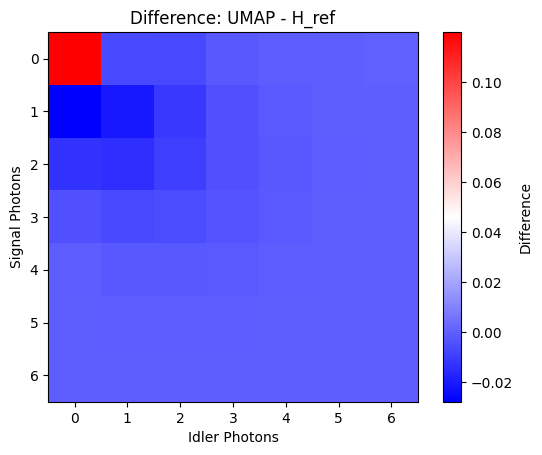

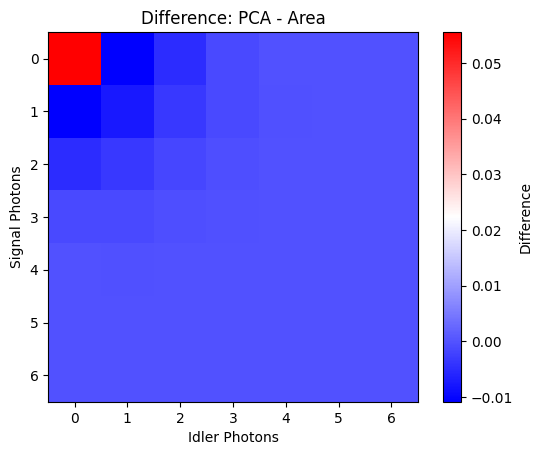

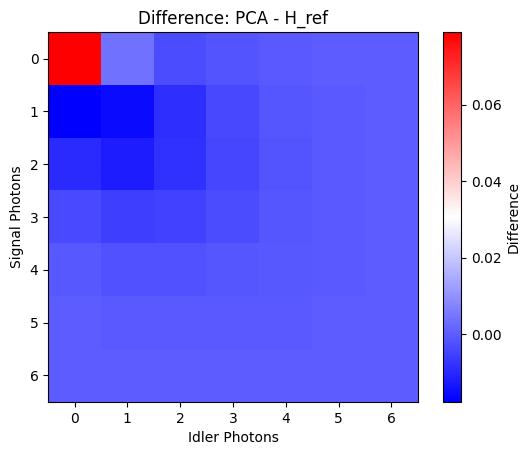

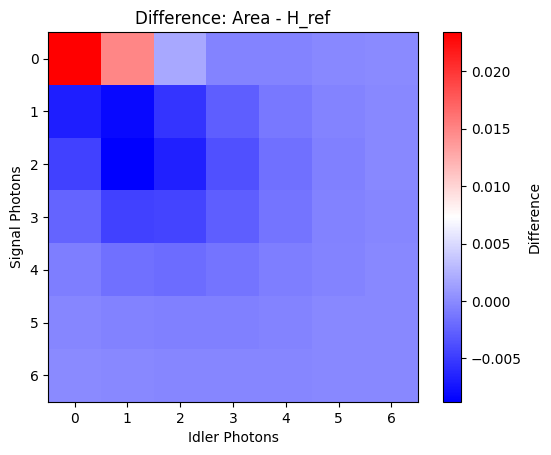

In [9]:
from itertools import combinations

idx_list = [idx_noNoise, idx_Noise_umap, idx_Noise_pca, idx_Noise_area]

# Generate all pmf matrices for the selected noise indices
pmf_list = []
for idx_noise in idx_list:
    params_ = params.params.copy()
    params_["eta_s"].value = 1 - loss[idx_loss]
    params_["eta_i"].value = 1 - loss[idx_loss]
    params_["noise_s"].value = noise[idx_noise]
    params_["noise_i"].value = noise[idx_noise]
    pmf = twinbeam_pmf(params_, cutoff=H_ref.shape[0])
    pmf_list.append(pmf[:H_ref.shape[0], :H_ref.shape[1]])

# Add H_ref to the list for comparison
matrices = pmf_list + [H_ref]
labels = ['noNoise', 'UMAP', 'PCA', 'Area', 'H_ref']

# Plot differences between all combinations

for (i, mat1), (j, mat2) in combinations(enumerate(matrices), 2):
    diff = mat1 - mat2
    plt.imshow(diff, cmap='bwr', interpolation='nearest')
    plt.colorbar(label='Difference')
    plt.xlabel('Idler Photons')
    plt.ylabel('Signal Photons')
    plt.title(f'Difference: {labels[i]} - {labels[j]}')
    plt.show()